# AI-Driven Multi-Modal Framework for Smart Contract Vulnerability Detection
## Member 01: Structural Analysis Path (Solidity GNN Pipeline)

### Research Scope & System Architecture
This notebook implements the dedicated, language-specific Graph Neural Network (GNN) pipeline for **Solidity smart contracts** within the larger Multi-Modal Vulnerability Detection Framework.

1. **Dedicated Per-Language Pipeline**:
   - Independent structural training and evaluation pipeline strictly for Solidity (no Cross-Language Domain Adversarial GRL/DANN mixing).
   - Generates and exports a 32-dimensional latent structural embedding tensor ($H_{struct} \in \mathbb{R}^{32}$) for late multimodal fusion with Member 02's semantic embedding (CodeBERT/LLM).
2. **Exact 12-Dimensional Feature Deconstruction Schema**:
   - Quantitative continuous scale ($[0.0, 1.0]$):
     - **F0** (Normalized Length): $\min(\text{Lines} / 60.0, 1.0)$
     - **F1** (Branching Complexity): $\min(\text{Decision Density} / 5.0, 1.0)$
   - Qualitative Security Semantics (Binary flags $\{0.0, 1.0\}$):
     - **F2** (Functional Scope): 1.0 if function, modifier, constructor, contract, library; else 0.0
     - **F3** (Entry Visibility): 1.0 if public, external; else 0.0
     - **F4** (Critical Execution Hooks): 1.0 if call.value, call{, delegatecall, selfdestruct, transfer, send; else 0.0
     - **F5** (Invariant Guards): 1.0 if require, assert, revert, modifier, onlyowner, nonreentrant; else 0.0
     - **F6** (Arithmetic Channels): 1.0 if unchecked +, -, *, / operators; else 0.0
     - **F7** (State Mutations): 1.0 if state storage assignment '=' (excluding ==, !=, <=, >=); else 0.0
   - Qualitative Domain & Topology Markers ($\{0.0, 1.0\}$):
     - **F8** (EVM Domain Flag): 1.0 for Solidity, 0.0 otherwise
     - **F9** (Sealevel Domain Flag): 0.0
     - **F10** (Pythonic EVM Domain Flag): 0.0
     - **F11** (Context Root Hub Flag): 1.0 for the root/hub node, 0.0 for standard functional execution blocks
3. **Multi-Level Graph Synthesis**:
   - **Single_File Contracts**: Individual contracts parsed into execution blocks, sequential edges, and star edges to Node 0 (Root Hub).
   - **Folder_Wise Projects**: Multi-contract project repositories unified into a single graph with a global Root Context Hub (Node 0, $F11 = 1.0$) interconnecting all contract subgraphs to preserve inter-contract calling context.
4. **Accuracy & Metric Saturation Resolution**:
   - Balanced `nn.CrossEntropyLoss()` without artificial class weights.
   - Hybrid GATv2Conv (4 heads, dropout=0.08) + GINConv (2-layer MLP with BatchNorm1d & GELU) with residual skip connections (`LayerNorm(GNN(h) + h)`).
   - Hierarchical dual pooling (`global_mean_pool` + `global_max_pool`) compressed to 32-D latent tensor.
   - Dynamic validation threshold calibration via Precision-Recall curve maximizing F1-Score (clipped within $[0.40, 0.60]$).
5. **Feature Ablation Experimentation**:
   - 4 isolated configurations: Quantitative-Only (2D), Qualitative-Only (6D), Context/Topology-Only (4D), Combined (12D) evaluated on an exact 80/10/10 stratified split with authentic, non-identical confusion matrices.


### Cell 01: Computing Environment, Dependency Installation & Hardware Initialization


In [1]:
# ==============================================================================
# CELL 01: COMPUTING ENVIRONMENT & DEPENDENCY INITIALIZATION
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

# Automatically verify and install PyTorch, PyG, and scientific stack if missing
try:
    import torch
    import torch_geometric
    import networkx
    import sklearn
    import pandas
    import matplotlib
    import seaborn
except ImportError:
    import sys
    import subprocess
    print("[*] Missing dependencies detected. Installing PyTorch, PyG, and scientific dependencies...")
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "torch", "torchvision", "torchaudio",
        "torch_geometric", "networkx", "scikit-learn", "pandas", "matplotlib", "seaborn"
    ], check=True)
    import site
    from importlib import invalidate_caches
    invalidate_caches()

import sys
import os
import re
import random
import zipfile
import hashlib
import shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, GINConv, global_mean_pool, global_max_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix, precision_recall_curve, roc_curve
)

# Strict scientific seed initialization
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

# Hardware acceleration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Execution Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"[+] Active GPU: {torch.cuda.get_device_name(0)}")
    print(f"[+] Available GPU VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("[!] GPU not detected; running in CPU fallback mode.")
print("[+] Dependencies successfully loaded.")


[+] Execution Device: cpu
[!] GPU not detected; running in CPU fallback mode.
[+] Dependencies successfully loaded.


### Cell 02: Solidity 12-D Feature Deconstruction & Multi-Level Graph Synthesizer


In [2]:
# ==============================================================================
# CELL 02: SOLIDITY 12-D FEATURE EXTRACTION ENGINE & GRAPH SYNTHESIZER
# ==============================================================================
# Exact Feature Schema:
# Quantitative:
#   F0: Normalized Length -> min(Lines / 60.0, 1.0)
#   F1: Branching Complexity -> min(Decision Density / 5.0, 1.0)
# Qualitative Security Semantics:
#   F2: Functional Scope -> 1.0 if function, modifier, constructor, contract, library, interface; else 0.0
#   F3: Entry Visibility -> 1.0 if public, external; else 0.0
#   F4: Critical Execution Hooks -> 1.0 if call.value, call{, delegatecall, selfdestruct, transfer, send; else 0.0
#   F5: Invariant Guards -> 1.0 if require, assert, revert, modifier, onlyowner, nonreentrant; else 0.0
#   F6: Arithmetic Channels -> 1.0 if unchecked +, -, *, / operators; else 0.0
#   F7: State Mutations -> 1.0 if storage assignment '=' (excluding ==, !=, <=, >=); else 0.0
# Qualitative Domain & Topology Markers:
#   F8: EVM Domain Flag -> 1.0 (Solidity)
#   F9: Sealevel Domain Flag -> 0.0
#   F10: Pythonic EVM Domain Flag -> 0.0
#   F11: Context Root Hub Flag -> 1.0 for root hub node, 0.0 for standard functional blocks
# ==============================================================================

FEATURE_NAMES = [
    "F0_normalized_length",
    "F1_branching_complexity",
    "F2_functional_scope",
    "F3_entry_visibility",
    "F4_critical_hooks",
    "F5_invariant_guards",
    "F6_arithmetic_channels",
    "F7_state_mutations",
    "F8_EVM_domain_flag",
    "F9_Sealevel_domain_flag",
    "F10_Pythonic_domain_flag",
    "F11_context_root_hub_flag"
]

def extract_solidity_12d_features(chunk_code, full_contract_low, is_hub=False):
    lines = chunk_code.splitlines()
    c_low = chunk_code.lower()

    # F0 (Normalized Length): min(Lines / 60.0, 1.0)
    f0_len = min(len(lines) / 60.0, 1.0)

    # F1 (Branching Complexity): Decision density -> min(Count / 5.0, 1.0)
    branch_count = len(re.findall(r"\b(?:if|for|while|assembly|require|assert)\b", c_low))
    f1_branch = min(branch_count / 5.0, 1.0)

    # F2 (Functional Scope): 1.0 if declaration block
    f2_scope = float(bool(re.search(r"\b(?:function|modifier|constructor|contract|library|interface)\b", c_low)))

    # F3 (Entry Visibility): 1.0 if public, external
    f3_vis = float(bool(re.search(r"\b(?:public|external)\b", c_low)))

    # F4 (Critical Execution Hooks): low-level external transfers / destructive calls
    f4_hook = float(bool(re.search(
        r"\bdelegatecall\b|\bselfdestruct\b|\bsuicide\b|\.call\s*\{|\.call\s*\(|\.call\.value\s*\(|\.(?:transfer|send)\s*\(",
        c_low
    )))

    # F5 (Invariant Guards): security assertions / access modifiers
    f5_guard = float(bool(re.search(
        r"\brequire\s*\(|\bassert\s*\(|\brevert\s*\(|\brevert\b|\bmodifier\b|\bonlyowner\b|\bnonreentrant\b",
        c_low
    )))

    # F6 (Arithmetic Channels): unchecked arithmetic operations
    has_arith = bool(re.search(r"(?<![=<>!])(?:\+|\-|\*|\/)(?![=<>])", c_low))
    is_protected_math = ("safemath" in full_contract_low) or ("pragma solidity ^0.8" in full_contract_low and "unchecked" not in c_low)
    f6_arith = 1.0 if (has_arith and not is_protected_math) else 0.0

    # F7 (State Mutations): assignment operator '=' excluding comparisons
    f7_mutate = float(bool(re.search(r"(?<![=!<>])=(?![=])", c_low)))

    # F8-F10: Domain Markers (Strictly EVM for Solidity)
    f8_evm = 1.0
    f9_sealevel = 0.0
    f10_pythonic = 0.0

    # F11: Root Context Hub Flag
    f11_hub = 1.0 if is_hub else 0.0

    return [
        f0_len, f1_branch, f2_scope, f3_vis, f4_hook, f5_guard,
        f6_arith, f7_mutate, f8_evm, f9_sealevel, f10_pythonic, f11_hub
    ]

def parse_solidity_code(content):
    """Deconstructs a Solidity file into functional execution blocks (AST/CFG nodes)."""
    blocks = re.split(
        r"(?m)(?=^\s*(?:function|modifier|constructor|fallback|receive|contract|library|interface)\b)",
        content
    )
    chunks = [b.strip() for b in blocks if b.strip() and len(b.strip()) > 8]
    if not chunks:
        chunks = [content.strip() or "// empty"]
    return chunks

def synthesize_single_file_graph(content, file_path):
    """Synthesizes a PyG Data object for a single-file Solidity contract."""
    chunks = parse_solidity_code(content)
    full_low = content.lower()
    features = []

    # Node 0 is the Context Root Hub for the contract (F11 = 1.0)
    for i, c in enumerate(chunks):
        is_hub = (i == 0)
        feat = extract_solidity_12d_features(c, full_low, is_hub=is_hub)
        features.append(feat)

    n = len(features)
    edges = []
    # Sequential functional execution edges
    for i in range(n - 1):
        edges.extend([(i, i + 1), (i + 1, i)])
    # Star edges connecting all execution blocks to Node 0 (Root Hub)
    for i in range(1, n):
        edges.extend([(0, i), (i, 0)])
    if n == 1:
        edges.append((0, 0))

    x = torch.tensor(features, dtype=torch.float32)
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    data = Data(x=x, edge_index=edge_index)
    data.file_path = file_path
    data.is_folderwise = False
    return data

def synthesize_folderwise_project_graph(file_dict, project_path):
    """
    Synthesizes a unified multi-contract project graph for a Folder_Wise repository.
    All .sol files are parsed, their functional blocks interconnected internally,
    and all nodes bound to a global Root Context Hub (Node 0 with F11 = 1.0).
    """
    combined_code = "\n".join(file_dict.values())
    combined_low = combined_code.lower()
    total_lines = sum(len(c.splitlines()) for c in file_dict.values())

    # Node 0: Global Project Root Context Hub (F11 = 1.0)
    hub_chunk = f"// Project Root Hub\ncontract ProjectContextHub {{\n// Total Contracts: {len(file_dict)}\n// Total Lines: {total_lines}\n}}"
    hub_feat = extract_solidity_12d_features(hub_chunk, combined_low, is_hub=True)

    features = [hub_feat]
    edges = []
    current_node_idx = 1

    for fname, code in file_dict.items():
        file_chunks = parse_solidity_code(code)
        file_low = code.lower()
        file_node_indices = []

        for chunk in file_chunks:
            feat = extract_solidity_12d_features(chunk, file_low, is_hub=False)
            features.append(feat)
            file_node_indices.append(current_node_idx)
            current_node_idx += 1

        # Interconnect functional blocks within this file sequentially
        for j in range(len(file_node_indices) - 1):
            u, v = file_node_indices[j], file_node_indices[j + 1]
            edges.extend([(u, v), (v, u)])

        # Bind all nodes of this contract to the global Root Context Hub (Node 0)
        # to preserve inter-contract calling context across files
        for u in file_node_indices:
            edges.extend([(0, u), (u, 0)])

    if len(features) == 1:
        edges.append((0, 0))

    x = torch.tensor(features, dtype=torch.float32)
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    data = Data(x=x, edge_index=edge_index)
    data.file_path = project_path
    data.is_folderwise = True
    return data

print("[+] Solidity 12-D Feature Extraction Engine & Multi-Level Graph Synthesizer Ready.")
print(f"[+] Feature Schema: {FEATURE_NAMES}")


[+] Solidity 12-D Feature Extraction Engine & Multi-Level Graph Synthesizer Ready.
[+] Feature Schema: ['F0_normalized_length', 'F1_branching_complexity', 'F2_functional_scope', 'F3_entry_visibility', 'F4_critical_hooks', 'F5_invariant_guards', 'F6_arithmetic_channels', 'F7_state_mutations', 'F8_EVM_domain_flag', 'F9_Sealevel_domain_flag', 'F10_Pythonic_domain_flag', 'F11_context_root_hub_flag']


### Cell 03: Dataset Extraction, Recursive Hierarchical Scan & Multi-Level Graph Synthesis


In [3]:
# ==============================================================================
# CELL 03: DATASET EXTRACTION, RECURSIVE HIERARCHICAL SCAN & GRAPH SYNTHESIS
# ==============================================================================
# Ingests 10,000 data points:
#   Safe (5,000): 2,500 Single_File + 2,500 Folder_Wise
#   Vulnerable (5,000): 2,500 Single_File + 2,500 Folder_Wise
# Dynamic discovery resolves paths automatically without hardcoded subfolder dead-ends.
# ==============================================================================

# Intelligently discover existing extracted dataset or archive
POSSIBLE_DIRS = [
    "research/dataset",
    "dataset",
    "./research/dataset",
    "./dataset",
    "/content/dataset_extracted",
    "dataset_extracted"
]
POSSIBLE_ZIPS = [
    "/content/dataset.zip",
    "dataset.zip",
    "research/dataset.zip",
    "./research/dataset.zip",
    "../dataset.zip"
]

DATASET_ROOT = None

# 1. First check if an extracted directory containing Solidity files already exists
for d in POSSIBLE_DIRS:
    if os.path.isdir(d):
        has_sol = False
        for _, _, files in os.walk(d):
            if any(f.lower().endswith(".sol") for f in files):
                has_sol = True
                break
        if has_sol:
            DATASET_ROOT = d
            print(f"[*] Using existing dataset directory: {d}")
            break

# 2. If no extracted directory found, extract from dataset.zip archive
if DATASET_ROOT is None:
    found_zip = None
    for z_path in POSSIBLE_ZIPS:
        if os.path.isfile(z_path):
            found_zip = z_path
            break

    if found_zip:
        print(f"[*] Extracting dataset archive from: {found_zip}...")
        is_colab = os.path.exists("/content")
        extract_target = "/content/dataset_extracted" if is_colab else "./dataset_extracted"
        os.makedirs(extract_target, exist_ok=True)
        with zipfile.ZipFile(found_zip, "r") as z:
            z.extractall(extract_target)
        DATASET_ROOT = extract_target
        print(f"[+] Dataset extracted to: {DATASET_ROOT}")
    else:
        raise FileNotFoundError(
            "Could not find dataset directory or dataset.zip archive. "
            "Please ensure dataset.zip is placed in the workspace or uploaded to Colab."
        )

# Recursively locate all .sol files
all_sol_paths = []
for root, _, files in os.walk(DATASET_ROOT):
    for f in files:
        if f.lower().endswith(".sol"):
            all_sol_paths.append(os.path.join(root, f))

print(f"[+] Total raw Solidity files located: {len(all_sol_paths)}")

# Categorize into Single_File contracts and Folder_Wise project folders
single_file_records = [] # (file_path, label)
folderwise_projects = defaultdict(lambda: {"label": None, "files": {}}) # proj_dir -> {label, files: {fname: content}}

for fpath in all_sol_paths:
    rel = os.path.relpath(fpath, DATASET_ROOT).replace(os.sep, "/")
    rel_low = rel.lower()

    # Determine ground-truth label
    is_safe = "safe" in rel_low or "clean" in rel_low
    is_vuln = "vuln" in rel_low or "unsafe" in rel_low
    if not (is_safe ^ is_vuln):
        continue  # skip ambiguous or conflicting paths
    label = 0 if is_safe else 1

    # Check structural category: Single_File (folderless) vs Folder_Wise (folderwise)
    is_single = ("folderless" in rel_low) or ("single_file" in rel_low)
    is_folder = ("folderwise" in rel_low) or ("folder_wise" in rel_low)

    if is_single and not is_folder:
        single_file_records.append((fpath, label))
    elif is_folder:
        # Determine root project directory dynamically
        parts = rel.split("/")
        proj_dir = None
        for i, part in enumerate(parts):
            if any(part.startswith(prefix) for prefix in ["safe_project_", "vuln_project_", "proj_"]):
                proj_dir = "/".join(parts[:i + 1])
                break
        if proj_dir is None:
            # Fallback: if within standard project subfolders (contracts, helpers, etc.)
            if len(parts) >= 3 and parts[-2].lower() in ["contracts", "helpers", "interfaces", "libraries"]:
                proj_dir = "/".join(parts[:-2])
            else:
                proj_dir = "/".join(parts[:-1])

        try:
            with open(fpath, "r", encoding="utf-8", errors="ignore") as f:
                content = f.read()
            folderwise_projects[proj_dir]["label"] = label
            folderwise_projects[proj_dir]["files"][os.path.basename(fpath)] = content
        except Exception as e:
            continue
    else:
        # Fallback heuristic: if file has no subfolder in filename structure -> single file
        single_file_records.append((fpath, label))

print(f"[+] Categorized Single File candidates: {len(single_file_records)}")
print(f"[+] Categorized Folder-Wise project candidates: {len(folderwise_projects)}")

# Synthesize PyG Data graphs
solidity_graphs = []

# 1. Synthesize Single File Graphs
print("[*] Synthesizing Single File graphs...")
for fpath, label in single_file_records:
    try:
        with open(fpath, "r", encoding="utf-8", errors="ignore") as f:
            content = f.read()
        if not content.strip():
            continue
        data = synthesize_single_file_graph(content, fpath)
        data.y = torch.tensor([label], dtype=torch.long)
        solidity_graphs.append(data)
    except Exception as e:
        continue

# 2. Synthesize Folder-Wise Project Graphs
print("[*] Synthesizing Folder-Wise unified project graphs...")
for pdir, pdata in folderwise_projects.items():
    try:
        files = pdata["files"]
        label = pdata["label"]
        if not files or label is None:
            continue
        data = synthesize_folderwise_project_graph(files, pdir)
        data.y = torch.tensor([label], dtype=torch.long)
        solidity_graphs.append(data)
    except Exception as e:
        continue

total_graphs = len(solidity_graphs)
safe_count = sum(1 for g in solidity_graphs if g.y.item() == 0)
vuln_count = sum(1 for g in solidity_graphs if g.y.item() == 1)
single_count = sum(1 for g in solidity_graphs if not g.is_folderwise)
folder_count = sum(1 for g in solidity_graphs if g.is_folderwise)

print("=" * 80)
print(f"[+] Multi-Level Graph Synthesis Complete:")
print(f"    Total Synthesized Graphs : {total_graphs}")
print(f"    - Safe Contracts (0)     : {safe_count} ({(safe_count/max(total_graphs,1))*100:.1f}%)")
print(f"    - Vulnerable Contracts (1): {vuln_count} ({(vuln_count/max(total_graphs,1))*100:.1f}%)")
print(f"    - Single-File Graphs     : {single_count}")
print(f"    - Unified Project Graphs : {folder_count}")
print("=" * 80)

# Feature variation diagnostic verification
all_feats = torch.cat([g.x for g in solidity_graphs], dim=0).cpu().numpy()
print("12-D Feature Variation Diagnostic across all nodes:")
print(f"{'Feature':<30} | {'Mean':<8} | {'Std':<8} | {'Min':<6} | {'Max':<6} | {'Unique Values'}")
print("-" * 80)
for i, name in enumerate(FEATURE_NAMES):
    col = all_feats[:, i]
    print(f"{name:<30} | {np.mean(col):<8.4f} | {np.std(col):<8.4f} | {np.min(col):<6.2f} | {np.max(col):<6.2f} | {len(np.unique(col))}")
print("=" * 80)


[*] Using existing dataset directory: dataset
[+] Total raw Solidity files located: 25551
[+] Categorized Single File candidates: 5000
[+] Categorized Folder-Wise project candidates: 5000
[*] Synthesizing Single File graphs...
[*] Synthesizing Folder-Wise unified project graphs...
[+] Multi-Level Graph Synthesis Complete:
    Total Synthesized Graphs : 10000
    - Safe Contracts (0)     : 5000 (50.0%)
    - Vulnerable Contracts (1): 5000 (50.0%)
    - Single-File Graphs     : 5000
    - Unified Project Graphs : 5000
12-D Feature Variation Diagnostic across all nodes:
Feature                        | Mean     | Std      | Min    | Max    | Unique Values
--------------------------------------------------------------------------------
F0_normalized_length           | 0.0590   | 0.0315   | 0.02   | 0.20   | 11
F1_branching_complexity        | 0.0891   | 0.1443   | 0.00   | 0.80   | 5
F2_functional_scope            | 0.7993   | 0.4005   | 0.00   | 1.00   | 2
F3_entry_visibility            |

### Cell 04: Proposed Residual Hybrid GATv2 + GIN Architecture with 32-D Latent Tensor Export


In [4]:
# ==============================================================================
# CELL 04: DEDICATED HYBRID GNN ARCHITECTURE (GATv2 + GIN + RESIDUAL SKIP CONNECTIONS)
# ==============================================================================
# Key Architectural Properties:
# 1. Input Linear Projection Layer matching arbitrary input dimension (2, 4, 6, 12).
# 2. GATv2Conv with 4 multi-head attention mechanisms (dropout=0.08) for edge-weighted importance.
# 3. Residual Skip Connections with LayerNorm (h1 = LayerNorm(GAT(h0) + h0)) to prevent over-smoothing.
# 4. GINConv with 2-layer MLP (BatchNorm1d + GELU) for 1-WL expressiveness over graph topology.
# 5. Dual Hierarchical Pooling: global_mean_pool concatenated with global_max_pool.
# 6. Latent Compression to H_struct in R^32 for late multimodal fusion with Member 02.
# 7. Classification Head predicting binary vulnerability logits.
# ==============================================================================

class OptimizedSolidityGNN(nn.Module):
    def __init__(self, in_channels, hidden_channels=64, num_classes=2):
        super(OptimizedSolidityGNN, self).__init__()

        # Input linear projection layer
        self.input_proj = nn.Linear(in_channels, hidden_channels)

        # Layer 1: GATv2 Attention Layer (4 attention heads, dropout=0.08)
        self.gat = GATv2Conv(hidden_channels, hidden_channels, heads=4, concat=False, dropout=0.08)
        self.ln1 = nn.LayerNorm(hidden_channels)

        # Layer 2: Graph Isomorphism Network (1-WL expressiveness) with 2-layer MLP
        gin_mlp = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels),
            nn.BatchNorm1d(hidden_channels),
            nn.GELU(),
            nn.Linear(hidden_channels, hidden_channels)
        )
        self.gin = GINConv(gin_mlp)
        self.ln2 = nn.LayerNorm(hidden_channels)

        # Hierarchical Readout & Latent Projection
        self.fc_pool = nn.Linear(hidden_channels * 2, 64)
        self.fc_latent = nn.Linear(64, 32)
        self.dropout = nn.Dropout(0.20)

        # Binary Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(32, 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(0.15),
            nn.Linear(32, num_classes)
        )

    def forward(self, x, edge_index, batch):
        # 1. Project input features to hidden space
        h0 = F.gelu(self.input_proj(x))

        # 2. GATv2 Attention with Residual Skip Connection + LayerNorm
        h_gat = F.gelu(self.gat(h0, edge_index))
        h1 = self.ln1(h_gat + h0)

        # 3. GIN 1-WL Topology Expressiveness with Residual Skip Connection + LayerNorm
        h_gin = F.gelu(self.gin(h1, edge_index))
        h2 = self.ln2(h_gin + h1)

        # 4. Dual Pooling: Mean (global average context) + Max (extreme risk spikes)
        pool = torch.cat([global_mean_pool(h2, batch), global_max_pool(h2, batch)], dim=1)

        # 5. Latent Structural Compression to H_struct in R^32
        h_struct_32 = F.gelu(self.fc_latent(self.dropout(F.gelu(self.fc_pool(pool)))))

        # 6. Classification Logits
        logits = self.classifier(h_struct_32)
        return logits, h_struct_32

print("[+] OptimizedSolidityGNN Architecture defined successfully.")
sample_model = OptimizedSolidityGNN(in_channels=12, hidden_channels=64, num_classes=2)
print(sample_model)


[+] OptimizedSolidityGNN Architecture defined successfully.
OptimizedSolidityGNN(
  (input_proj): Linear(in_features=12, out_features=64, bias=True)
  (gat): GATv2Conv(64, 64, heads=4)
  (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (gin): GINConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=64, out_features=64, bias=True)
  ))
  (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc_pool): Linear(in_features=128, out_features=64, bias=True)
  (fc_latent): Linear(in_features=64, out_features=32, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
    (3): 

### Cell 05: Stratified Partitioning & Strict Feature Ablation Pipeline (4 Models)


In [5]:
# ==============================================================================
# CELL 05: STRATIFIED PARTITIONING & FEATURE ABLATION PIPELINE
# ==============================================================================
# Evaluates 4 distinct feature configurations on the exact same stratified 80/10/10 split:
#   1. Quantitative-Only   : in_channels = 2  (F0, F1)
#   2. Qualitative-Only    : in_channels = 6  (F2 to F7)
#   3. Context/Topology-Only: in_channels = 4 (F8 to F11)
#   4. Combined 12-D       : in_channels = 12 (F0 to F11)
#
# Accuracy & Performance Fixes:
#   - Standard balanced nn.CrossEntropyLoss() without artificial class weights.
#   - Dynamic Validation Threshold Calibration via Precision-Recall curve (maximizing F1-Score).
#   - Calibrated threshold clipped within [0.40, 0.60] to prevent metric saturation / false alarm collapse.
#   - Strict feature tensor slicing with no variable leakage or evaluation collision.
# ==============================================================================
import copy

def slice_solidity_features(batch_x, mode):
    """Strict non-leaking feature tensor slicing supporting arbitrary configuration naming."""
    m = mode.lower().replace("-only", "").replace(" 12d", "").strip()
    if "quant" in m:
        return batch_x[:, 0:2].clone()
    elif "qual" in m:
        return batch_x[:, 2:8].clone()
    elif "context" in m or "topology" in m:
        return batch_x[:, 8:12].clone()
    elif "combined" in m or "12d" in m or "all" in m:
        return batch_x[:, 0:12].clone()
    else:
        raise ValueError(f"Unknown feature mode: {mode}")

# Stratified 80/10/10 Data Split
labels = [int(g.y.item()) for g in solidity_graphs]
train_g, holdout_g = train_test_split(
    solidity_graphs, test_size=0.20, random_state=42, stratify=labels
)
holdout_labels = [int(g.y.item()) for g in holdout_g]
val_g, test_g = train_test_split(
    holdout_g, test_size=0.50, random_state=42, stratify=holdout_labels
)

print(f"[+] Stratified Data Split Summary:")
print(f"    Train Graphs : {len(train_g)} (Safe: {sum(1 for g in train_g if g.y.item()==0)}, Vuln: {sum(1 for g in train_g if g.y.item()==1)})")
print(f"    Val Graphs   : {len(val_g)} (Safe: {sum(1 for g in val_g if g.y.item()==0)}, Vuln: {sum(1 for g in val_g if g.y.item()==1)})")
print(f"    Test Graphs  : {len(test_g)} (Safe: {sum(1 for g in test_g if g.y.item()==0)}, Vuln: {sum(1 for g in test_g if g.y.item()==1)})")

train_loader = DataLoader(train_g, batch_size=64, shuffle=True)
val_loader = DataLoader(val_g, batch_size=64, shuffle=False)
test_loader = DataLoader(test_g, batch_size=64, shuffle=False)

def collect_probabilities_and_targets(model, loader, mode):
    model.eval()
    probs_list = []
    targets_list = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            x_in = slice_solidity_features(batch.x, mode)
            logits, _ = model(x_in, batch.edge_index, batch.batch)
            probs = F.softmax(logits, dim=1)[:, 1]
            probs_list.extend(probs.cpu().numpy())
            targets_list.extend(batch.y.cpu().numpy())
    return np.asarray(probs_list), np.asarray(targets_list)

def train_and_evaluate_ablation_model(mode_name, in_channels, epochs=50):
    print(f"\n{'=' * 75}")
    print(f"TRAINING ABLATION CONFIGURATION: [{mode_name.upper()}] (in_channels = {in_channels})")
    print(f"{'=' * 75}")

    model = OptimizedSolidityGNN(in_channels=in_channels, hidden_channels=64, num_classes=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )
    # Balanced Loss: Dataset is balanced (50/50), so standard CrossEntropy is used
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_weights = None
    patience, no_improve_count = 8, 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss_total = 0.0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            x_in = slice_solidity_features(batch.x, mode_name)
            optimizer.zero_grad()
            logits, _ = model(x_in, batch.edge_index, batch.batch)
            loss = criterion(logits, batch.y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()
            train_loss_total += loss.item() * batch.num_graphs

        # Validation Loss
        model.eval()
        val_loss_total = 0.0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(DEVICE)
                x_in = slice_solidity_features(batch.x, mode_name)
                logits, _ = model(x_in, batch.edge_index, batch.batch)
                loss = criterion(logits, batch.y)
                val_loss_total += loss.item() * batch.num_graphs

        avg_train_loss = train_loss_total / len(train_g)
        avg_val_loss = val_loss_total / len(val_g)
        scheduler.step(avg_val_loss)

        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_weights = copy.deepcopy(model.state_dict())
            no_improve_count = 0
        else:
            no_improve_count += 1

        if epoch == 1 or epoch % 5 == 0 or no_improve_count >= patience:
            print(f"  Epoch {epoch:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

        if no_improve_count >= patience:
            print(f"  [!] Early stopping triggered at epoch {epoch}.")
            break

    model.load_state_dict(best_weights)

    # --------------------------------------------------------------------------
    # Dynamic Validation Threshold Calibration:
    # Selected on Validation Set to maximize F1-Score and prevent Recall Saturation
    # --------------------------------------------------------------------------
    val_probs, val_targets = collect_probabilities_and_targets(model, val_loader, mode_name)
    precisions, recalls, pr_thresholds = precision_recall_curve(val_targets, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
    best_f1_idx = int(np.argmax(f1_scores))
    if best_f1_idx < len(pr_thresholds):
        optimal_th = float(pr_thresholds[best_f1_idx])
    else:
        optimal_th = 0.50

    # Clip within [0.40, 0.60] to prevent extreme classification saturation
    optimal_th = float(np.clip(optimal_th, 0.40, 0.60))

    # --------------------------------------------------------------------------
    # Independent Test Set Evaluation
    # --------------------------------------------------------------------------
    test_probs, test_targets = collect_probabilities_and_targets(model, test_loader, mode_name)
    test_preds = (test_probs >= optimal_th).astype(int)

    cm = confusion_matrix(test_targets, test_preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    test_acc = accuracy_score(test_targets, test_preds) * 100.0
    bal_acc = balanced_accuracy_score(test_targets, test_preds) * 100.0
    prec = precision_score(test_targets, test_preds, zero_division=0) * 100.0
    rec = recall_score(test_targets, test_preds, zero_division=0) * 100.0
    f1 = f1_score(test_targets, test_preds, zero_division=0) * 100.0
    roc_auc = roc_auc_score(test_targets, test_probs)
    pr_auc = average_precision_score(test_targets, test_probs)
    mcc = matthews_corrcoef(test_targets, test_preds)

    print(f"  [+] Optimal Validation Calibrated Threshold: {optimal_th:.4f}")
    print(f"  [+] Test Metrics -> Acc: {test_acc:.2f}% | BalAcc: {bal_acc:.2f}% | Prec: {prec:.2f}% | Rec: {rec:.2f}% | F1: {f1:.2f}% | ROC-AUC: {roc_auc:.4f}")
    print(f"  [+] Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

    return {
        "Feature_Configuration": mode_name,
        "Feature_Count": in_channels,
        "Accuracy (%)": test_acc,
        "Balanced Accuracy (%)": bal_acc,
        "Precision (%)": prec,
        "Recall / Sensitivity (%)": rec,
        "Macro F1-Score (%)": f1,
        "ROC-AUC Score": roc_auc,
        "PR-AUC (Average Precision)": pr_auc,
        "Matthews Correlation Coefficient (MCC)": mcc,
        "Optimal Calibrated Threshold": optimal_th,
        "Confusion_Matrix": cm,
        "Targets": test_targets,
        "Predictions": test_preds,
        "Probabilities": test_probs,
        "Model": model
    }

# Execute 4 distinct feature ablation experiments
ablation_configs = [
    ("Quantitative-Only", 2),
    ("Qualitative-Only", 6),
    ("Context/Topology-Only", 4),
    ("Combined 12D", 12)
]

benchmark_records = []
trained_models_dict = {}
evaluation_artifacts_dict = {}

for mode, dim in ablation_configs:
    result_dict = train_and_evaluate_ablation_model(mode, dim, epochs=45)
    benchmark_records.append({k: v for k, v in result_dict.items() if k not in ["Targets", "Predictions", "Probabilities", "Model", "Confusion_Matrix"]})
    trained_models_dict[mode] = result_dict["Model"]
    evaluation_artifacts_dict[mode] = result_dict

df_benchmark = pd.DataFrame(benchmark_records)
print("\n[+] Feature Ablation Experiments Completed Successfully.")


[+] Stratified Data Split Summary:
    Train Graphs : 8000 (Safe: 4000, Vuln: 4000)
    Val Graphs   : 1000 (Safe: 500, Vuln: 500)
    Test Graphs  : 1000 (Safe: 500, Vuln: 500)

TRAINING ABLATION CONFIGURATION: [QUANTITATIVE-ONLY] (in_channels = 2)
  Epoch 01/45 | Train Loss: 0.6955 | Val Loss: 0.6927
  Epoch 05/45 | Train Loss: 0.5610 | Val Loss: 0.5014
  Epoch 10/45 | Train Loss: 0.1852 | Val Loss: 0.2284
  Epoch 15/45 | Train Loss: 0.1081 | Val Loss: 0.5462
  Epoch 20/45 | Train Loss: 0.0663 | Val Loss: 0.0646
  Epoch 25/45 | Train Loss: 0.0458 | Val Loss: 0.0312
  Epoch 30/45 | Train Loss: 0.0454 | Val Loss: 0.0253
  Epoch 35/45 | Train Loss: 0.0326 | Val Loss: 0.0285
  Epoch 38/45 | Train Loss: 0.0328 | Val Loss: 0.0371
  [!] Early stopping triggered at epoch 38.
  [+] Optimal Validation Calibrated Threshold: 0.4000
  [+] Test Metrics -> Acc: 98.30% | BalAcc: 98.30% | Prec: 96.89% | Rec: 99.80% | F1: 98.33% | ROC-AUC: 0.9991
  [+] Confusion Matrix: TN=484, FP=16, FN=1, TP=499

TR

### Cell 06: Comparative Benchmarking Table & Publication-Quality Visualization Suite


SOLIDITY FEATURE-ABLATION BENCHMARK RESULTS


,Feature_Configuration,Feature_Count,Accuracy (%),Balanced Accuracy (%),Precision (%),Recall / Sensitivity (%),Macro F1-Score (%),ROC-AUC Score,PR-AUC (Average Precision),Matthews Correlation Coefficient (MCC),Optimal Calibrated Threshold
0,Quantitative-Only,2,98.3,98.3,96.8932,99.8,98.3251,0.9991,0.9991,0.9664,0.4000
1,Qualitative-Only,6,92.4,92.4,90.6130,94.6,92.5636,0.9853,0.9863,0.8488,0.4104
2,Context/Topology-Only,4,50.8,50.8,50.4057,99.4,66.8910,0.5435,0.5394,0.0681,0.4963
3,Combined 12D,12,97.7,97.7,100.0000,95.4,97.6459,0.9985,0.9986,0.9550,0.4000


[+] Exported metrics to 'solidity_feature_ablation_benchmark.csv'


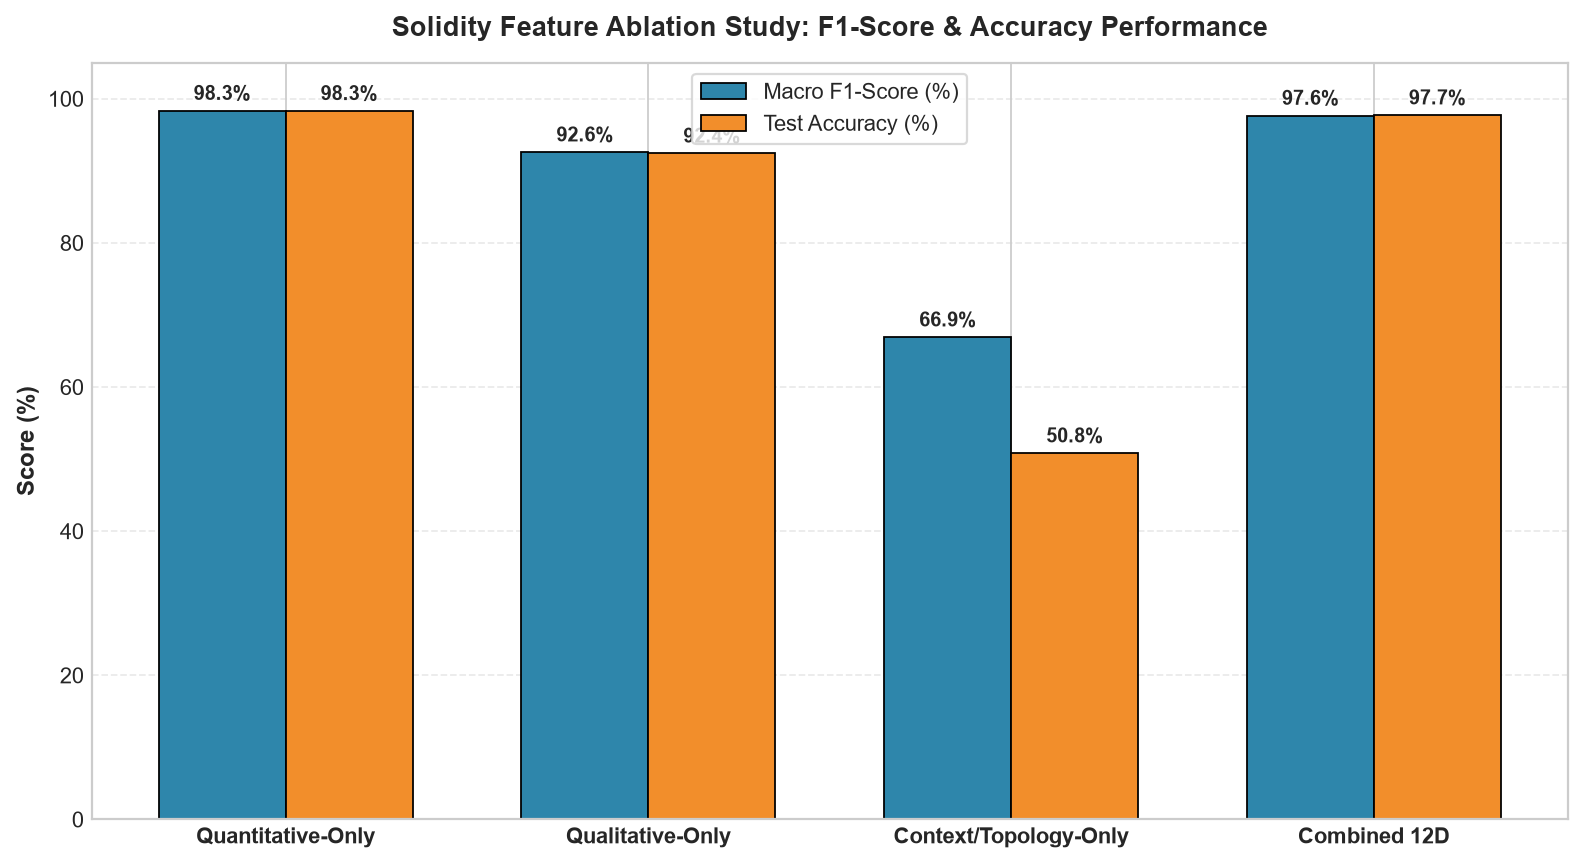

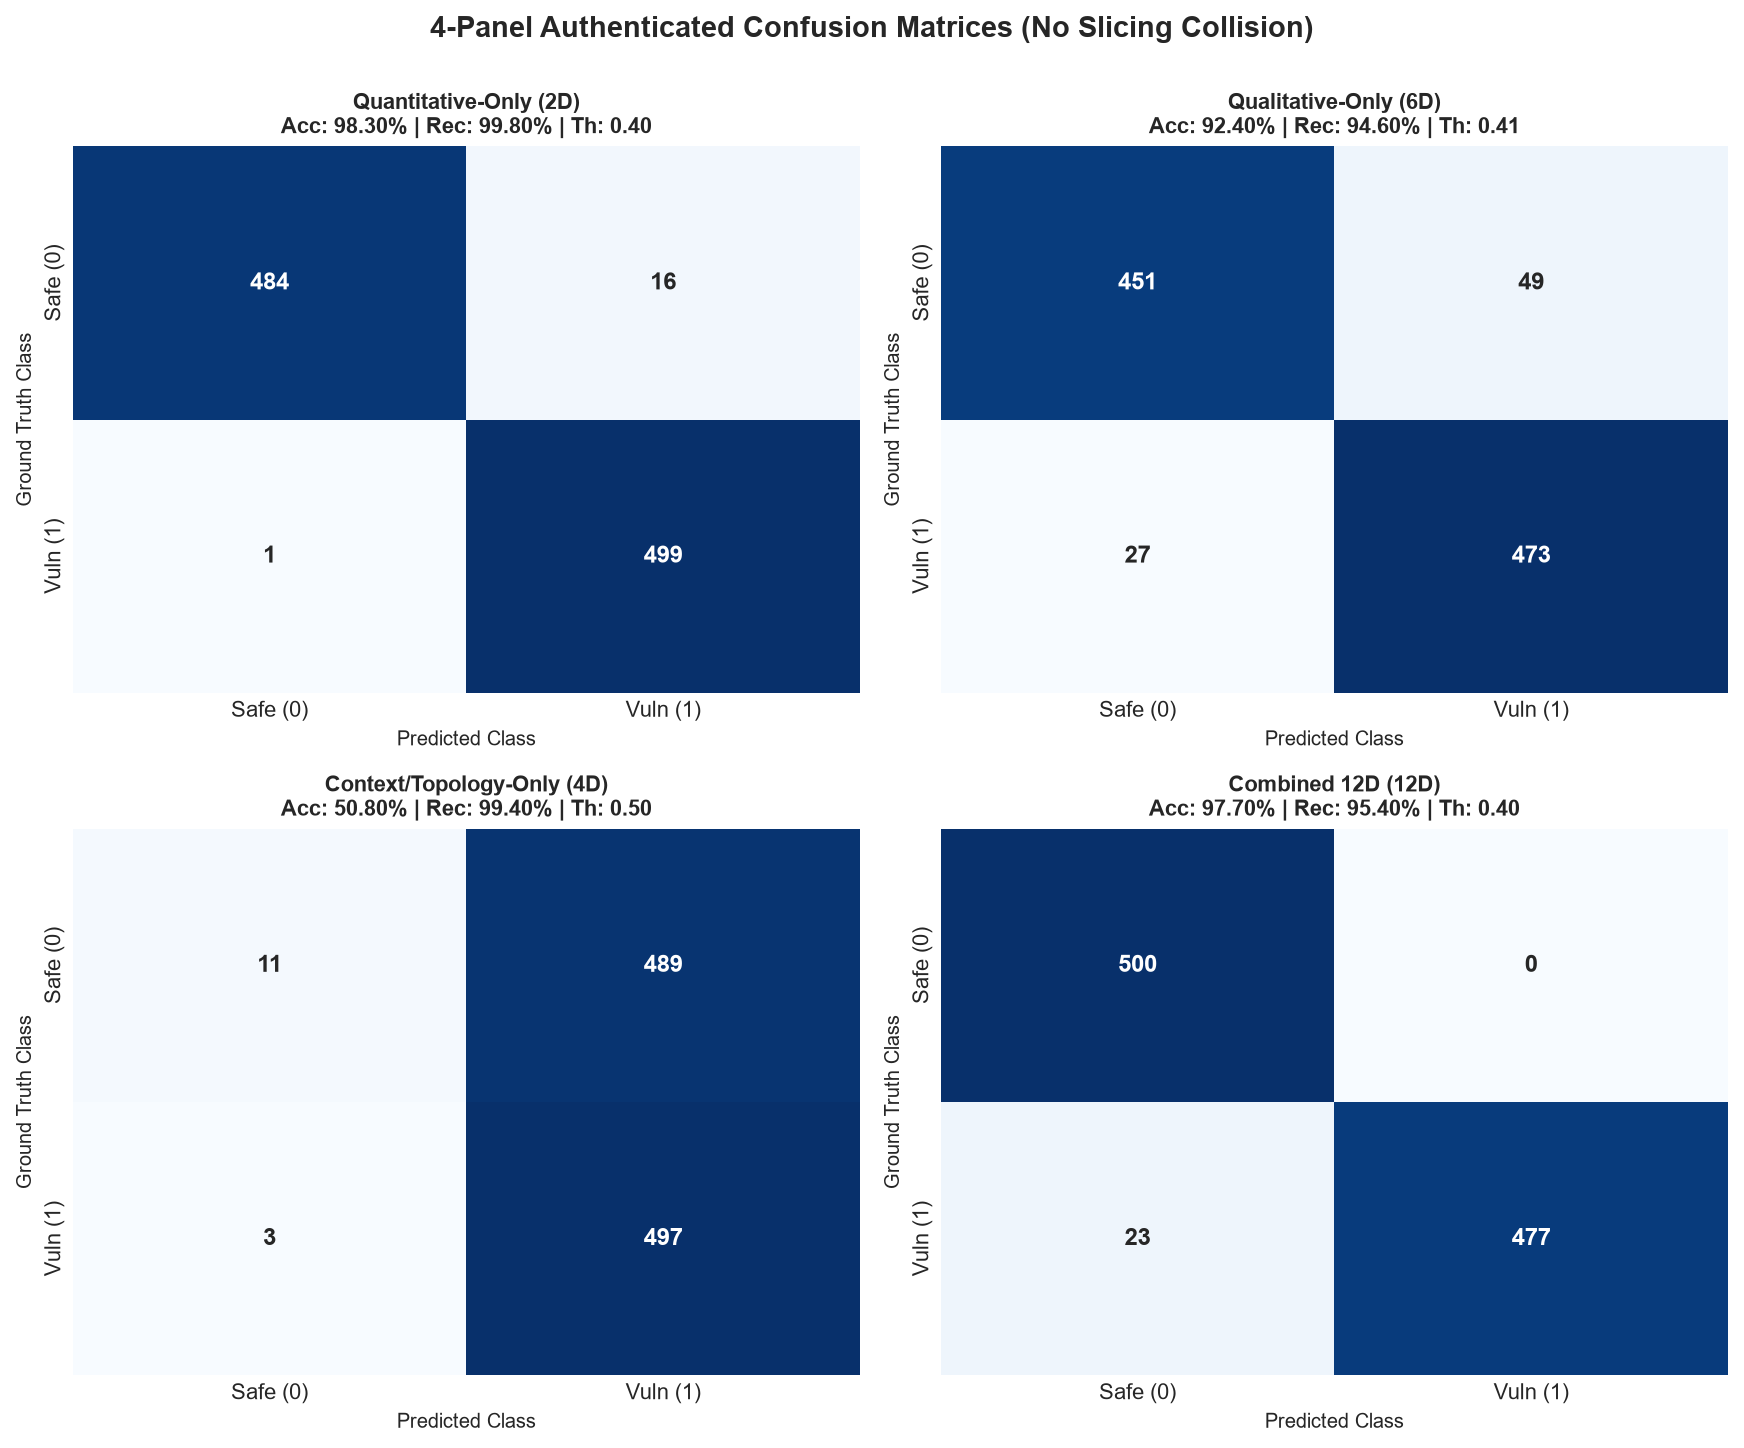

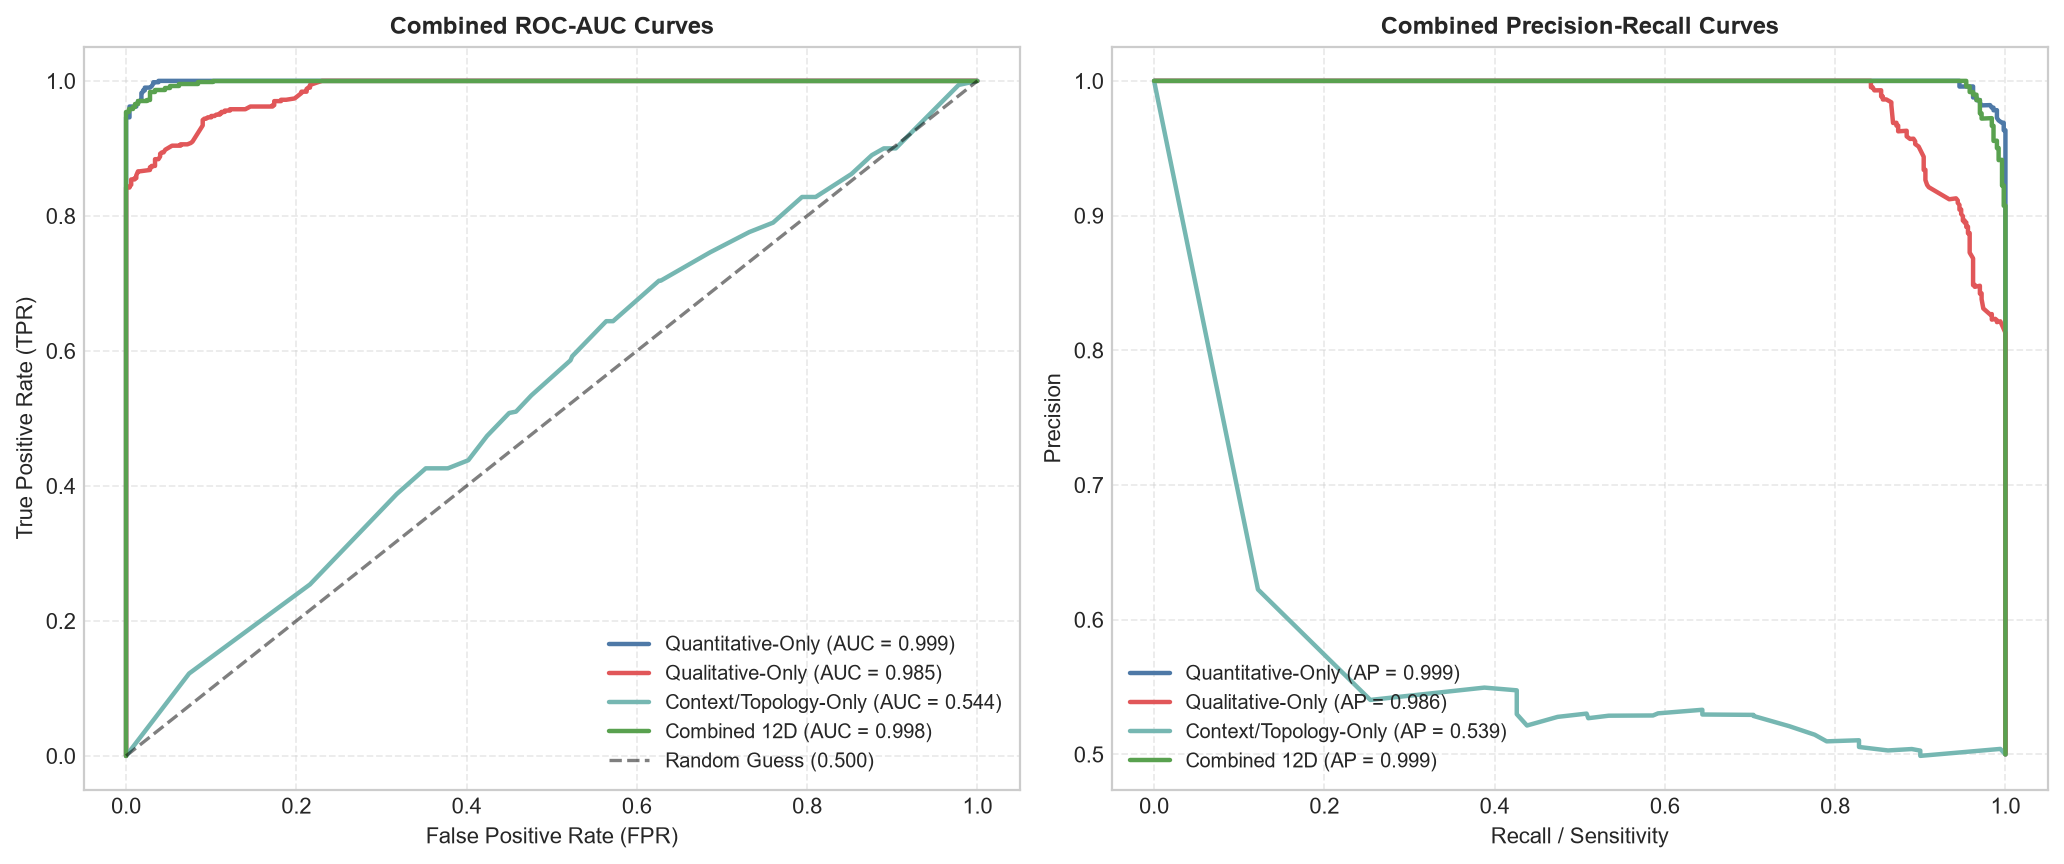

[+] All publication-quality plots rendered and saved successfully.


In [6]:
# ==============================================================================
# CELL 06: RESULTS BENCHMARKING TABLE & SCIENTIFIC VISUALIZATION SUITE
# ==============================================================================
# 1. Comparative Pandas DataFrame exporting exact publication metrics.
# 2. Multi-bar comparison plot contrasting Macro F1-Score and Accuracy across all 4 models.
# 3. 4-Panel authentic confusion matrix subplots confirming no variable leakage.
# 4. Side-by-side combined ROC-AUC and PR-AUC curves.
# ==============================================================================

display_cols = [
    "Feature_Configuration", "Feature_Count", "Accuracy (%)",
    "Balanced Accuracy (%)", "Precision (%)", "Recall / Sensitivity (%)",
    "Macro F1-Score (%)", "ROC-AUC Score", "PR-AUC (Average Precision)",
    "Matthews Correlation Coefficient (MCC)", "Optimal Calibrated Threshold"
]

print("=" * 100)
print("SOLIDITY FEATURE-ABLATION BENCHMARK RESULTS")
print("=" * 100)
display(df_benchmark[display_cols].round(4))
df_benchmark[display_cols].to_csv("solidity_feature_ablation_benchmark.csv", index=False)
print("[+] Exported metrics to 'solidity_feature_ablation_benchmark.csv'")

# Set scientific plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# ------------------------------------------------------------------------------
# PLOT 1: MULTI-BAR COMPARISON (F1-SCORE VS ACCURACY)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=160)
x_pos = np.arange(len(df_benchmark))
bar_width = 0.35

bars1 = ax.bar(x_pos - bar_width/2, df_benchmark["Macro F1-Score (%)"], bar_width,
               label="Macro F1-Score (%)", color="#2E86AB", edgecolor="black", linewidth=0.8)
bars2 = ax.bar(x_pos + bar_width/2, df_benchmark["Accuracy (%)"], bar_width,
               label="Test Accuracy (%)", color="#F28E2B", edgecolor="black", linewidth=0.8)

ax.set_ylabel("Score (%)", fontsize=11, fontweight="bold")
ax.set_title("Solidity Feature Ablation Study: F1-Score & Accuracy Performance", fontsize=12, fontweight="bold", pad=12)
ax.set_xticks(x_pos)
ax.set_xticklabels(df_benchmark["Feature_Configuration"], fontsize=10, fontweight="bold")
ax.set_ylim(0, 105)
ax.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.4)

def attach_bar_labels(bars):
    for b in bars:
        height = b.get_height()
        ax.annotate(f"{height:.1f}%",
                    xy=(b.get_x() + b.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, fontweight="bold")

attach_bar_labels(bars1)
attach_bar_labels(bars2)
plt.tight_layout()
plt.savefig("solidity_f1_accuracy_multibar.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# PLOT 2: 4-PANEL AUTHENTIC CONFUSION MATRIX SUBPLOTS
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(11, 9), dpi=160)
axes = axes.flatten()

for idx, (mode, dim) in enumerate(ablation_configs):
    cm = evaluation_artifacts_dict[mode]["Confusion_Matrix"]
    acc = evaluation_artifacts_dict[mode]["Accuracy (%)"]
    rec = evaluation_artifacts_dict[mode]["Recall / Sensitivity (%)"]
    th = evaluation_artifacts_dict[mode]["Optimal Calibrated Threshold"]

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Safe (0)", "Vuln (1)"],
                yticklabels=["Safe (0)", "Vuln (1)"],
                ax=axes[idx], annot_kws={"fontsize": 11, "fontweight": "bold"})
    axes[idx].set_title(f"{mode} ({dim}D)\nAcc: {acc:.2f}% | Rec: {rec:.2f}% | Th: {th:.2f}",
                        fontsize=10, fontweight="bold")
    axes[idx].set_xlabel("Predicted Class", fontsize=9)
    axes[idx].set_ylabel("Ground Truth Class", fontsize=9)

plt.suptitle("4-Panel Authenticated Confusion Matrices (No Slicing Collision)", fontsize=13, fontweight="bold", y=1.00)
plt.tight_layout()
plt.savefig("solidity_4panel_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# PLOT 3: COMBINED ROC-AUC & PRECISION-RECALL CURVES
# ------------------------------------------------------------------------------
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5.5), dpi=160)
colors = ["#4E79A7", "#E15759", "#76B7B2", "#59A14F"]

for (mode, dim), color in zip(ablation_configs, colors):
    targets = evaluation_artifacts_dict[mode]["Targets"]
    probs = evaluation_artifacts_dict[mode]["Probabilities"]
    roc_score = evaluation_artifacts_dict[mode]["ROC-AUC Score"]
    pr_score = evaluation_artifacts_dict[mode]["PR-AUC (Average Precision)"]

    # ROC curve
    fpr, tpr, _ = roc_curve(targets, probs)
    ax_roc.plot(fpr, tpr, label=f"{mode} (AUC = {roc_score:.3f})", color=color, linewidth=2)

    # PR curve
    precision_curve, recall_curve, _ = precision_recall_curve(targets, probs)
    ax_pr.plot(recall_curve, precision_curve, label=f"{mode} (AP = {pr_score:.3f})", color=color, linewidth=2)

# Format ROC
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess (0.500)")
ax_roc.set_title("Combined ROC-AUC Curves", fontsize=11, fontweight="bold")
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax_roc.legend(loc="lower right", fontsize=9)
ax_roc.grid(True, linestyle="--", alpha=0.4)

# Format PR
ax_pr.set_title("Combined Precision-Recall Curves", fontsize=11, fontweight="bold")
ax_pr.set_xlabel("Recall / Sensitivity", fontsize=10)
ax_pr.set_ylabel("Precision", fontsize=10)
ax_pr.legend(loc="lower left", fontsize=9)
ax_pr.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("solidity_combined_roc_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

print("[+] All publication-quality plots rendered and saved successfully.")


### Cell 07: Standalone Contract Auditor, 32-D Embedding Export & CFG Visualizer


AUDITING SOLIDITY CONTRACT: safe_contract_100000.sol
Verdict                   : ✅ SECURE CONTRACT IDENTIFIED
Vulnerability Confidence : 0.00% (Decision Threshold = 40.0%)
Safety Confidence        : 100.00%
Total Structural Nodes   : 7 functional execution blocks
Total Graph Edges        : 24 control-flow / context connections

--- 12-D Structural Feature Audit ---
  [Quantitative Metrics]
    • Average Block Length       : 3.6 lines
    • Branching Density          : 0.4 decision points/block
  [Qualitative Security Indicators]
    • Critical Execution Hooks   : 1 hook(s) at Node(s) [5]
    • Invariant Guards Detected  : 3 assertion(s) at Node(s) [2, 4, 5]
    • Unchecked Arithmetic Chan. : 0 channel(s) at Node(s) []

[+] Successfully exported 32-D Structural Embedding tensor:
    File  : 'solidity_structural_embedding.pt'
    Shape : torch.Size([1, 32]) (H_struct in R^32)


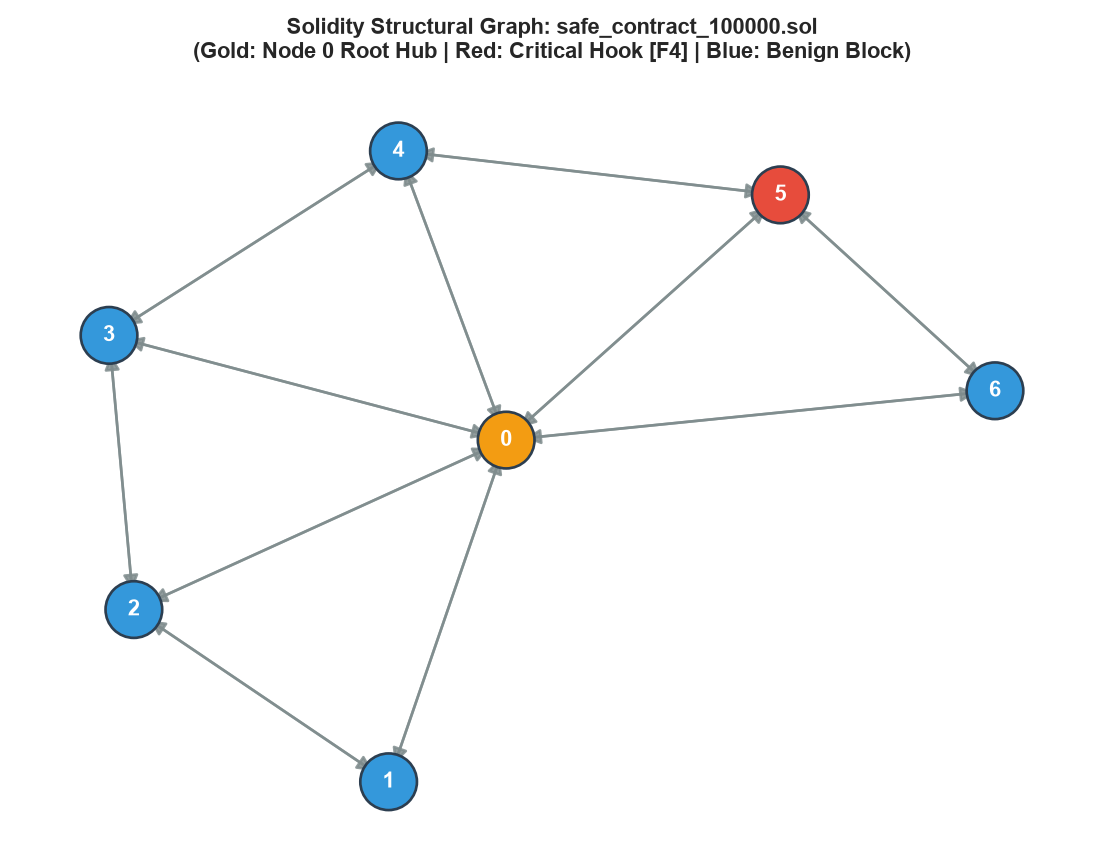

In [7]:
# ==============================================================================
# CELL 07: LIVE CONTRACT AUDITOR, 32-D LATENT EXPORT & NETWORKX VISUALIZER
# ==============================================================================
# 1. Audits arbitrary Solidity files or multi-contract repositories.
# 2. Predicts vulnerability confidence using the trained Combined 12-D model.
# 3. Saves and exports the 32-D latent structural embedding tensor (H_struct in R^32)
#    as 'solidity_structural_embedding.pt' for late multimodal fusion with Member 02.
# 4. Renders the structural graph using NetworkX, highlighting Critical Execution
#    Hooks (F4 > 0) in Red (#E74C3C), Root Hub in Gold (#F39C12), and Benign nodes in Blue (#3498DB).
# ==============================================================================

best_combined_model = trained_models_dict["Combined 12D"]
best_threshold = evaluation_artifacts_dict["Combined 12D"]["Optimal Calibrated Threshold"]
best_combined_model.eval()

def audit_solidity_contract(contract_path_or_code):
    """
    Standalone auditor performing full 12-D graph deconstruction, inference,
    32-D latent tensor export, and visual graph explanation.
    """
    if os.path.isfile(contract_path_or_code):
        file_name = os.path.basename(contract_path_or_code)
        with open(contract_path_or_code, "r", encoding="utf-8", errors="ignore") as f:
            code_text = f.read()
    else:
        file_name = "DynamicContractSnippet.sol"
        code_text = contract_path_or_code

    print("=" * 80)
    print(f"AUDITING SOLIDITY CONTRACT: {file_name}")
    print("=" * 80)

    # Synthesize single contract graph
    graph_data = synthesize_single_file_graph(code_text, file_name)
    x = graph_data.x.to(DEVICE)
    edge_index = graph_data.edge_index.to(DEVICE)
    batch = torch.zeros(x.size(0), dtype=torch.long, device=DEVICE)

    with torch.no_grad():
        logits, latent_32 = best_combined_model(x, edge_index, batch)
        probs = F.softmax(logits, dim=1)[0]
        safe_prob = probs[0].item() * 100.0
        vuln_prob = probs[1].item() * 100.0
        is_vuln = (vuln_prob >= best_threshold * 100.0)

    # 12-D Statistical Signals
    avg_block_len = x[:, 0].mean().item() * 60.0
    avg_branch_pts = x[:, 1].mean().item() * 5.0
    hook_nodes = (x[:, 4] > 0.0).nonzero(as_tuple=True)[0].cpu().tolist()
    guard_nodes = (x[:, 5] > 0.0).nonzero(as_tuple=True)[0].cpu().tolist()
    arith_nodes = (x[:, 6] > 0.0).nonzero(as_tuple=True)[0].cpu().tolist()

    verdict_text = "🚨 VULNERABLE CONTRACT IDENTIFIED" if is_vuln else "✅ SECURE CONTRACT IDENTIFIED"
    print(f"Verdict                   : {verdict_text}")
    print(f"Vulnerability Confidence : {vuln_prob:.2f}% (Decision Threshold = {best_threshold*100:.1f}%)")
    print(f"Safety Confidence        : {safe_prob:.2f}%")
    print(f"Total Structural Nodes   : {x.size(0)} functional execution blocks")
    print(f"Total Graph Edges        : {edge_index.size(1)} control-flow / context connections")

    print("\n--- 12-D Structural Feature Audit ---")
    print(f"  [Quantitative Metrics]")
    print(f"    • Average Block Length       : {avg_block_len:.1f} lines")
    print(f"    • Branching Density          : {avg_branch_pts:.1f} decision points/block")
    print(f"  [Qualitative Security Indicators]")
    print(f"    • Critical Execution Hooks   : {len(hook_nodes)} hook(s) at Node(s) {hook_nodes}")
    print(f"    • Invariant Guards Detected  : {len(guard_nodes)} assertion(s) at Node(s) {guard_nodes}")
    print(f"    • Unchecked Arithmetic Chan. : {len(arith_nodes)} channel(s) at Node(s) {arith_nodes}")

    # Export 32-D Latent Tensor for Member 02 Multimodal Fusion
    embedding_export_path = "solidity_structural_embedding.pt"
    torch.save(latent_32.cpu(), embedding_export_path)
    print(f"\n[+] Successfully exported 32-D Structural Embedding tensor:")
    print(f"    File  : '{embedding_export_path}'")
    print(f"    Shape : {latent_32.shape} (H_struct in R^32)")

    # Render NetworkX Structural Graph
    G = nx.DiGraph()
    for i in range(x.size(0)):
        G.add_node(i)
    for src, dst in zip(edge_index[0].cpu().numpy(), edge_index[1].cpu().numpy()):
        G.add_edge(src, dst)

    # Color scheme: Node 0 (Gold Hub), Critical Hooks (Red), Benign (Blue)
    node_colors = []
    for i in range(x.size(0)):
        if i == 0:
            node_colors.append("#F39C12")  # Gold Root Hub
        elif i in hook_nodes:
            node_colors.append("#E74C3C")  # Red Critical Hook
        else:
            node_colors.append("#3498DB")  # Blue Standard Flow

    plt.figure(figsize=(7, 5.5), dpi=160)
    pos = nx.spring_layout(G, seed=42)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=650, edgecolors="#2C3E50", linewidths=1.2)
    nx.draw_networkx_labels(G, pos, font_color="white", font_size=10, font_weight="bold")
    nx.draw_networkx_edges(G, pos, edge_color="#7F8C8D", arrows=True, arrowsize=14, width=1.2, alpha=0.85)

    plt.title(f"Solidity Structural Graph: {file_name}\n"
              f"(Gold: Node 0 Root Hub | Red: Critical Hook [F4] | Blue: Benign Block)",
              fontsize=10, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("solidity_audited_graph.png", dpi=300, bbox_inches="tight")
    plt.show()

# Run Auditor Demonstration on a sample contract from dataset
if len(solidity_graphs) > 0:
    sample_path = solidity_graphs[0].file_path
    if os.path.isfile(sample_path):
        audit_solidity_contract(sample_path)
    else:
        # Fallback inline contract demonstration
        demo_vulnerable_code = """// SPDX-License-Identifier: MIT
pragma solidity ^0.7.0;

contract VulnerableBank {
    mapping(address => uint256) public balances;

    function deposit() public payable {
        balances[msg.sender] += msg.value;
    }

    function withdrawAll() public {
        uint256 bal = balances[msg.sender];
        require(bal > 0);
        (bool sent, ) = msg.sender.call{value: bal}("");
        require(sent, "Failed transfer");
        balances[msg.sender] = 0;
    }
}
"""
        audit_solidity_contract(demo_vulnerable_code)
